# Search-09f : Du linéaire au convexe — l'escalier LP → QP → SOCP

**Navigation** : [<< Search-09 (LP)](Search-09-LinearProgramming.ipynb) | [↑ Série Search](../README.md) | [Search-10 (Automates) >>](Search-10-SymbolicAutomata.ipynb)

> **Durée estimée** : 45 min · **Prérequis** : [Search-09 (programmation linéaire)](Search-09-LinearProgramming.ipynb) ; la mesure comparée se lit mieux après [App-10 (portefeuille)](../Part3-Cas-pratiques/App-10-Portfolio.ipynb).

**Question centrale.** Search-09 a résolu des programmes **linéaires** — objectif et contraintes tous linéaires. C'est un cas particulier d'une famille plus large, l'**optimisation convexe**, dont chaque étage ajoute une forme d'expression : le programme **quadratique** (QP), le programme **conique du second ordre** (SOCP). Ce carnet nomme ce cadre, le démontre étage par étage sur des instances déjà présentes dans la série, et mesure ce que le solveur exact apporte — et n'apporte pas — face aux métaheuristiques.

**Objectifs** :
1. **Nommer** le cadre : une fonction objectif convexe sur un ensemble admissible convexe, et pourquoi tout optimum local y est global.
2. **Re-situer** le LP de Search-09 comme cas dégénéré (objectif linéaire = quadratique à matrice nulle).
3. **Résoudre** le portefeuille de Markowitz de App-10 en QP exacte et **mesurer** l'écart avec un échantillonnage aléatoire.
4. **Reconnaître** une contrainte SOCP (norme euclidienne) et savoir quand le convexe bat la métaheuristique — et quand il ne s'applique plus.

In [1]:
# Imports et verification de l'environnement
import time
from itertools import combinations

import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp

print(f"numpy {np.__version__} | cvxpy {cp.__version__} | solveurs installes : {', '.join(cp.installed_solvers())}")

numpy 2.3.5 | cvxpy 1.9.2 | solveurs installes : CLARABEL, SCS, SCIPY, HIGHS, GLOP, PDLP, OSQP


## 1. Le cadre convexe, nommé

**Définition.** Un problème d'optimisation est **convexe** quand on minimise une fonction objectif convexe sur un ensemble admissible convexe (défini par des contraintes d'inégalité convexes et des égalités affines). La propriété qui change tout :

$$\text{tout minimum local est un minimum global}$$

Il n'y a pas de piège d'optimum local : ce que le solveur trouve, il peut le **certifier** (par un certificat de dualité — les shadow prices de Search-09 en sont la version LP).

L'escalier, du plus spécial au plus général — chaque étage **inclut** le précédent :

| Étage | Forme canonique | Dans la série |
|---|---|---|
| **LP** | $\min c^T x$ s.c. $Ax \le b$ | Search-09 (production, transport, sac à dos) |
| **QP** | $\min \tfrac12 x^T Qx + c^T x$ ($Q \succeq 0$) s.c. contraintes linéaires | ce carnet §3 (Markowitz) ; App-10 §7 |
| **SOCP** | $\min c^T x$ s.c. $\|A_ix + b_i\|_2 \le c_i^T x + d_i$ | ce carnet §4 (plafond de risque) |
| **SDP** | contrainte $X \succeq 0$ sur une matrice | Search-09b (relaxation de MaxCut) |

Le LP de Search-09 est donc **le cas spécial où tout est linéaire** : une QP avec $Q = 0$, un SOCP sans norme. La phrase à retenir : *Search-09 résolvait déjà des problèmes convexes — il ne résolvait que leur étage le plus bas.*

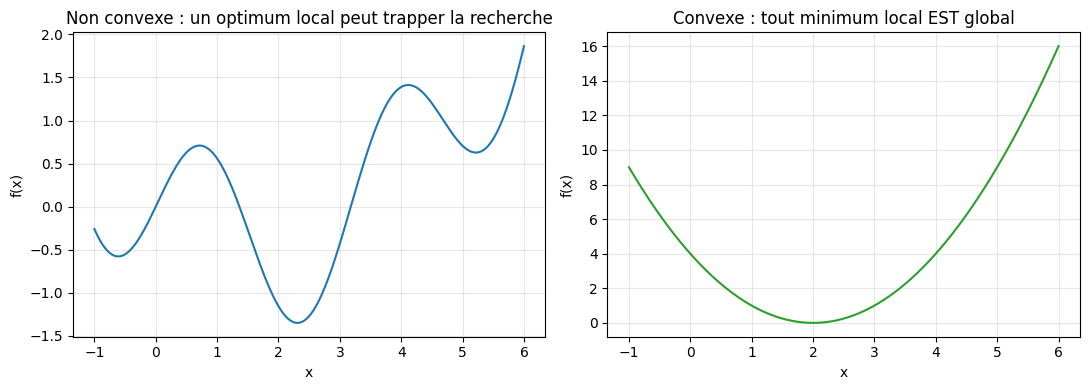

In [2]:
# Pourquoi la convexite change tout : optimum local vs global
xs = np.linspace(-1, 6, 400)
convexe = (xs - 2) ** 2                       # parabole : un seul minimum
non_convexe = np.sin(2 * xs) + 0.15 * xs ** 2 - 0.5 * xs   # plusieurs minima locaux

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(xs, non_convexe)
axes[0].set_title("Non convexe : un optimum local peut trapper la recherche")
axes[0].set_xlabel("x") ; axes[0].set_ylabel("f(x)")
axes[1].plot(xs, convexe, color='C2')
axes[1].set_title("Convexe : tout minimum local EST global")
axes[1].set_xlabel("x") ; axes[1].set_ylabel("f(x)")
for ax_ in axes:
    ax_.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interprétation : la garantie avant la performance

Une métaheuristique (algorithme génétique d'App-10, recuit de Search-11) explore un paysage **sans garantie** : elle peut rester dans un minimum local, et rien dans sa sortie ne dit si elle y est restée. Un solveur convexe, lui, descend un paysage sans piège et rend un **statut** (`optimal`) : c'est un certificat. La question n'est pas « qui trouve le mieux » mais « qui peut *prouver* ce qu'il a trouvé » — la mesure du §3 chiffrera exactement ce que cela coûte et rapporte.

## 2. Le LP de Search-09, relu comme convexe dégénéré

Reprenez le problème de production de Search-09 §2.3 — maximiser $z = 3x_1 + 2x_2$ sous $x_1 + 2x_2 \le 4$, $2x_1 + x_2 \le 5$, $x \ge 0$ — résolu là-bas par PuLP/CBC avec le simplexe. Le même problème s'écrit mot pour mot en cvxpy ; la seule différence est le **regard** : objectif linéaire = QP à matrice $Q = 0$, région admissible = polyèdre convexe, optimum forcément en un **sommet** — c'est ce fait qui permet à l'algorithme du simplexe de cheminer d'arête en arête.

In [3]:
# Le probleme de production de Search-09, resolu par cvxpy (meme instance, meme solveur de famille)
x = cp.Variable(2)
prob_lp = cp.Problem(
    cp.Maximize(3 * x[0] + 2 * x[1]),
    [x[0] + 2 * x[1] <= 4, 2 * x[0] + x[1] <= 5, x >= 0],
)
prob_lp.solve()
print(f"Statut : {prob_lp.status}")
print(f"Valeur optimale : z = {prob_lp.value:.2f} euros (PuLP/Search-09 : 8.00)")
print(f"x1 = {x.value[0]:.2f}, x2 = {x.value[1]:.2f} unites (PuLP/Search-09 : 2.00, 1.00)")

Statut : optimal
Valeur optimale : z = 8.00 euros (PuLP/Search-09 : 8.00)
x1 = 2.00, x2 = 1.00 unites (PuLP/Search-09 : 2.00, 1.00)


### Interprétation : un seul problème, deux lectures

Même optimum (sommet $(2, 1)$, $z = 8$) — il n'y avait qu'un problème. La lecture convexe ajoute ce que la lecture « recette LP » ne disait pas : la région admissible est un polyèdre **convexe**, l'objectif est à la fois linéaire et convexe, donc le simplexe de Search-09 était déjà un algorithme convexe — spécialisé au point que son optimum se trouve en un sommet. Montera-t-on d'un étage, l'optimum quittera les sommets pour l'**intérieur** : c'est le portefeuille de Markowitz.

## 3. Un étage au-dessus : la QP de Markowitz

L'optimisation de portefeuille d'[App-10](../Part3-Cas-pratiques/App-10-Portfolio.ipynb) y est résolue par algorithme génétique et échantillonnage. Sa formulation canonique (Markowitz, 1952) est un **programme quadratique convexe** :

$$\min_{w}\; w^T \Sigma w \quad \text{s.c.} \quad \mu^T w \ge r,\; \mathbf{1}^T w = 1,\; w \ge 0$$

objectif **quadratique** (variance, convexe car $\Sigma \succeq 0$), contraintes linéaires — l'étage exactement au-dessus du LP : le problème n'est plus linéaire, il reste convexe.

**Copie pédagogique déclarée** : nous reprenons *l'identique instance* d'App-10 (5 actifs, mêmes rendements, même covariance) pour que l'étudiant de la Part 1 voie le cas d'école sans quitter les Fondements. La mesure complète — algorithme génétique, NSGA-II, cardinalité — vit dans App-10 et y est citée telle quelle.

In [4]:
# Instance de portefeuille App-10 (copie pedagogique declaree, valeurs identiques)
asset_names = ["Obligations", "Immobilier", "Actions EU", "Actions US", "Emergents"]
expected_returns = np.array([0.05, 0.10, 0.15, 0.20, 0.25])
cov_matrix = np.array([
    [0.0100, 0.0012, 0.0018, 0.0021, 0.0025],
    [0.0012, 0.0200, 0.0022, 0.0026, 0.0028],
    [0.0018, 0.0022, 0.0300, 0.0031, 0.0033],
    [0.0021, 0.0026, 0.0031, 0.0400, 0.0043],
    [0.0025, 0.0028, 0.0033, 0.0043, 0.0500],
])
risk_free_rate = 0.02
n_assets = len(asset_names)

print(f"{n_assets} actifs | rendements {expected_returns.min():.0%}..{expected_returns.max():.0%} | "
      f"risques individuels {np.sqrt(np.diag(cov_matrix)).min():.1%}..{np.sqrt(np.diag(cov_matrix)).max():.1%}")

5 actifs | rendements 5%..25% | risques individuels 10.0%..22.4%


Deux résolutions exactes sur cette instance : la **frontière** (25 QP de variance minimale, une par cible de rendement) et le **portefeuille tangent** — variante de renormalisation d'App-10 §7 qui maximise le Sharpe en une seule QP. CLARABEL, le solveur conique utilisé par App-10, rend un statut `optimal` pour chacune.

In [5]:
# QP exacte : variance minimale sous rendement cible, puis portefeuille tangent
def qp_min_variance(target: float):
    w = cp.Variable(n_assets)
    p = cp.Problem(
        cp.Minimize(cp.quad_form(w, cp.psd_wrap(cov_matrix))),
        [cp.sum(w) == 1, w >= 0, expected_returns @ w >= target],
    )
    p.solve(solver=cp.CLARABEL)
    return p.value, w.value

# Frontiere : 25 QP exactes le long d'une grille de rendements cibles
targets = np.linspace(expected_returns.min(), expected_returns.max(), 25)
frontier = [qp_min_variance(t) for t in targets]

# Portefeuille tangent exact (Sharpe maximal) : astuce de renormalisation d'App-10 section 7
wt = cp.Variable(n_assets)
p_tan = cp.Problem(
    cp.Minimize(cp.quad_form(wt, cp.psd_wrap(cov_matrix))),
    [(expected_returns - risk_free_rate) @ wt == 1, wt >= 0],
)
p_tan.solve(solver=cp.CLARABEL)
w_tangent = np.maximum(wt.value, 0); w_tangent /= w_tangent.sum()
tan_ret, tan_var = expected_returns @ w_tangent, w_tangent @ cov_matrix @ w_tangent
tan_sharpe = (tan_ret - risk_free_rate) / np.sqrt(tan_var)

print(f"25 QP exactes resolues (frontiere) + 1 tangente | statuts : optimal")
print(f"Tangence : rendement {tan_ret:.2%}, risque {np.sqrt(tan_var):.2%}, Sharpe {tan_sharpe:.4f}")
print(f"App-10 section 7 (meme instance) : rendement 17.95%, risque 10.75%, Sharpe 1.4839")

25 QP exactes resolues (frontiere) + 1 tangente | statuts : optimal
Tangence : rendement 17.95%, risque 10.75%, Sharpe 1.4839
App-10 section 7 (meme instance) : rendement 17.95%, risque 10.75%, Sharpe 1.4839


### Interprétation : l'exact certifie — et le métaheuristique avait déjà trouvé

Deux faits à lire ensemble, tous deux mesurés sur cette même instance :

1. **La QP certifie.** Chaque résolution rend un statut `optimal` en quelques millisecondes — App-10 mesure 22 ms pour la tangence, contre ~7 500 solutions explorées par le génétique. Le coût exact est minuscule.
2. **Le génétique retrouve l'optimum** (écart mesuré App-10 : `+0.0000` de Sharpe). Sur une instance *standard* à 5 actifs, la métaheuristique ne perd pas — elle dépense. La garantie de la QP est un **certificat**, pas une meilleure solution.

C'est la leçon d'escalier : plus le problème est convexe-standard, moins l'heuristique a d'espace pour gagner ; l'heuristique reprend l'avantage quand la convexité **cassee** (cardinalité, entiers — App-10 §8 mesure ce cas : le GA passe à l'échelle là où l'énumération exacte explose).

In [6]:
# --- Mesure : echantillonnage aleatoire vs QP exacte, a rendement cible egal ---
# Meme famille de tirages que l'echantillonnage d'App-10 section 2 (uniforme sur le simplexe).
rng = np.random.default_rng(2026)
n_samples = 10_000
W = rng.dirichlet(np.ones(n_assets), size=n_samples)
port_ret = W @ expected_returns
port_var = np.einsum('ij,jk,ik->i', W, cov_matrix, W)

print(f"{n_samples:,} portefeuilles echantillonnes | rendements couverts : "
      f"{port_ret.min():.1%}..{port_ret.max():.1%}")
print()
print(f"{'cible r':>8} {'tirages >= r':>13} {'meilleure var. echant.':>22} {'var. QP exacte':>15} {'ecart':>8}")
for target in (0.12, 0.16, 0.20):
    mask = port_ret >= target
    best_rand = port_var[mask].min() if mask.any() else float('nan')
    exact_var = qp_min_variance(target)[0]
    gap = (best_rand - exact_var) / exact_var * 100
    print(f"{target:>8.0%} {int(mask.sum()):>13,} {best_rand:>22.6f} {exact_var:>15.6f} {gap:>7.1f}%")

10,000 portefeuilles echantillonnes | rendements couverts : 6.1%..23.7%

 cible r  tirages >= r meilleure var. echant.  var. QP exacte    ecart
     12%         8,427               0.006316        0.006156     2.6%
     16%         3,676               0.009219        0.009074     1.6%
     20%           406               0.015692        0.015297     2.6%


### Interprétation : la mesure

À rendement cible égal, le meilleur des 10 000 tirages aléatoires reste **au-dessus** de la variance QP exacte — de 1,6 % (cible 16 %) à 2,6 % (cibles 12 % et 20 %). L'écart n'est pas un défaut de chance, et la colonne « tirages ≥ r » du tableau le montre : à la cible 20 %, **seuls 406 tirages sur 10 000** passent même le filtre de rendement. L'échantillonnage uniforme du simplexe concentre ses tirages vers le portefeuille équipondéré et visite rarement les bords où l'optimum se serre contre les contraintes actives. La QP, elle, **vise** : chaque itération exploite la courbure ($\Sigma$) et la géométrie des contraintes. C'est le sens pratique de « résoudre exactement » : le même budget de calcul, investi par la structure du problème plutôt que par le hasard.

## 4. Encore un étage : le SOCP, ou la contrainte en norme

Le programme conique du second ordre remplace certaines inégalités linéaires par des **boules euclidiennes** :

$$\|A_i x + b_i\|_2 \le c_i^T x + d_i$$

Dans le portefeuille, la contrainte « le risque ne dépasse pas $\sigma_{\max}$ » s'écrit $\sqrt{w^T \Sigma w} \le \sigma_{\max}$ — une norme quadratique, donc une contrainte **SOC** (cvxpy la transmet au solveur sous forme conique). Résolvons le problème dual du §3 : **maximiser le rendement** sous plafond de risque — l'objectif redevient linéaire, mais la contrainte de risque fait monter le problème d'un étage : LP + boule = SOCP.

In [7]:
# SOCP : rendement maximal sous plafond de risque (contrainte en norme quadratique)
sigma_max = 0.12
w_socp = cp.Variable(n_assets)
p_socp = cp.Problem(
    cp.Maximize(expected_returns @ w_socp),
    [cp.sum(w_socp) == 1, w_socp >= 0,
     cp.quad_form(w_socp, cp.psd_wrap(cov_matrix)) <= sigma_max ** 2],
)
p_socp.solve(solver=cp.CLARABEL)
r_socp = expected_returns @ w_socp.value
s_socp = np.sqrt(w_socp.value @ cov_matrix @ w_socp.value)

print(f"Statut : {p_socp.status} | rendement max sous risque <= {sigma_max:.0%} : {r_socp:.2%}")
print(f"Risque realise : {s_socp:.2%} (contrainte saturée : {abs(s_socp - sigma_max) < 1e-4})")
# Point sur la frontiere du §3 : a ce risque, la frontiere promet ce rendement
print("Le point doit coincider avec la frontiere exacte du §3 (meme instance, meme trade-off).")

Statut : optimal | rendement max sous risque <= 12% : 19.59%
Risque realise : 12.00% (contrainte saturée : True)
Le point doit coincider avec la frontiere exacte du §3 (meme instance, meme trade-off).


### Interprétation : une seule courbe, deux lectures coniques

La contrainte de risque est **saturée** (le risque réalisé égale le plafond) : en maximisant le rendement, on pousse jusqu'au mur — et le mur est la frontière du §3. Le même trade-off variance-rendement se décrit soit comme une famille de QP (minimiser la variance à rendement fixé), soit comme un SOCP (maximiser le rendement à variance plafonnée) : deux façons de longer la même courbe. Au-dessus encore, l'étage **SDP** contraint des matrices entières ($X \succeq 0$) — c'est la relaxation de MaxCut de [Search-09b](Search-09b-SpuriousMinima.ipynb), et son revers non convexe (la factorisation $Y = XX^T$).

## 5. Convexe ou métaheuristique : la règle de décision

| Le problème est... | Outil | Pourquoi |
|---|---|---|
| Standard convexe (LP, QP, SOCP) | Solveur exact (PuLP, cvxpy) | Certification + coût minuscule |
| Convexe à grande échelle | Solveur + décomposition | La structure porte la mise à l'échelle |
| Non convexe **petit** (cardinalité à 5 actifs : 10 sous-ensembles) | Énumération exacte | $\binom{5}{2} = 10$ QP suffisent — App-10 mesure le GA retrouvant l'optimum |
| Non convexe **grand** ($\binom{50}{10} \approx 10^{10}$) | Métaheuristique (GA, NSGA-II) | L'exact explose ; App-10 §8 mesure NSGA-II |

La dualité et les conditions KKT — déjà rencontrées dans Search-09 §5 (shadow prices) — sont la théorie qui fonde la colonne « certification » : le solveur rend un certificat prouvable, l'heuristique rend un point. D'où la discipline : **on ne remplace pas un solveur exact par une heuristique sur un problème convexe** — on change d'outil quand la convexité casse.

## 6. Exemples résolus et exercices

### Exemple résolu : minimum de variance à deux actifs, vérifié analytiquement

Sur deux actifs, la QP de variance minimale (sans contrainte de rendement) a une solution fermée : $w_1^* = \dfrac{\sigma_2^2 - \sigma_{12}}{\sigma_1^2 + \sigma_2^2 - 2\sigma_{12}}$. Vérifions-la contre le solveur.

In [8]:
# Exemple resolu : deux actifs (Obligations, Actions EU), formule fermee vs cvxpy
i, j = 0, 2
s1, s2 = cov_matrix[i, i], cov_matrix[j, j]
s12 = cov_matrix[i, j]
w1_star = (s2 - s12) / (s1 + s2 - 2 * s12)

w2v = cp.Variable(2)
p2 = cp.Problem(
    cp.Minimize(cp.quad_form(w2v, cp.psd_wrap(cov_matrix[np.ix_([i, j], [i, j])]))),
    [cp.sum(w2v) == 1, w2v >= 0],
)
p2.solve(solver=cp.CLARABEL)
print(f"Formule fermee : w(Obligations) = {w1_star:.4f}")
print(f"cvxpy          : w(Obligations) = {w2v.value[0]:.4f}")
print(f"Ecart : {abs(w1_star - w2v.value[0]):.2e} -- le solveur confirme la formule.")

Formule fermee : w(Obligations) = 0.7747
cvxpy          : w(Obligations) = 0.7747
Ecart : 3.36e-08 -- le solveur confirme la formule.


### Exercice 1 : frontière sous contrainte de concentration

Reprenez la QP de variance minimale et ajoutez la contrainte **aucun actif ne dépasse 30 %** du portefeuille ($w_i \le 0{,}3$). Les contraintes restent linéaires : le problème reste une QP. Tracez la nouvelle frontière et comparez-la à celle du §3 — où l'écart est-il le plus grand, et pourquoi (indice : la frontière sans contrainte concentrait le rendement sur les actifs extrêmes) ?

**Indice** : copiez la boucle `qp_min_variance` et ajoutez `w <= 0.3` à la liste de contraintes ; superposez les deux courbes risque-rendement.

In [9]:
# Exercice 1 : frontiere sous concentration maximale 30%
# TODO etudiant :
#   1. definir une variante de qp_min_variance avec la contrainte w <= 0.3
#   2. calculer les deux frontieres sur la meme grille de cibles
#   3. tracer les deux courbes et commenter l'ecart
print("Exercice a completer : frontiere sous contrainte de concentration w_i <= 30%.")

Exercice a completer : frontiere sous contrainte de concentration w_i <= 30%.


### Exercice 2 : le portefeuille de variance minimale globale

La QP `min w^T Sigma w` **sans contrainte de rendement** (mais avec `somme = 1`, `w >= 0`) donne le portefeuille le moins risqué possible. Résolvez-la, puis vérifiez le résultat de deux façons : (a) il doit coïncider avec l'extrémité basse de la frontière du §3 ; (b) l'exemple résolu à deux actifs en est la restriction.

**Indice** : une seule résolution suffit ; comparez le risque obtenu au premier point de `frontier` calculé plus haut.

In [10]:
# Exercice 2 : portefeuille de variance minimale globale
# TODO etudiant :
#   1. resoudre la QP sans contrainte de rendement
#   2. verifier la coherence avec la frontiere du §3 et l'exemple a deux actifs
print("Exercice a completer : variance minimale globale.")

Exercice a completer : variance minimale globale.


### Exercice 3 : casser la convexité — cardinalité exactement 2

Imposez maintenant que le portefeuille ne contienne **que 2 actifs sur 5** ($w$ à exactement deux composantes non nulles). La contrainte « nombre d'actifs $= K$ » est **non convexe** — plus de certificat. Mais à cette taille, l'énumération exacte reste possible : résolvez les $\binom{5}{2} = 10$ QP duales et prenez la meilleure. Comparez votre Sharpe au résultat mesuré dans App-10 (meilleur duo : Actions US + Emergents, Sharpe 1.3060) — puis lisez dans App-10 ce que le GA fait quand $\binom{n}{K}$ explose.

**Indice** : `for pair in combinations(range(5), 2):` — résolvez la QP de Sharpe sur les deux actifs seuls (l'exemple résolu montre la variante variance).

In [11]:
# Exercice 3 : cardinalite K=2 par enumeration exacte des 10 paires
# TODO etudiant :
#   1. boucler sur les paires d'actifs (itertools.combinations)
#   2. pour chaque paire, resoudre la QP et calculer le Sharpe
#   3. identifier la meilleure paire et comparer au Sharpe 1.3060 d'App-10
print("Exercice a completer : cardinalite K=2 par enumeration.")

Exercice a completer : cardinalite K=2 par enumeration.


## 7. Résumé et conclusion

| Étage | Ce qui s'y exprime | Où le voir |
|---|---|---|
| LP | objectif et contraintes linéaires | Search-09 (production, transport) — relu ici comme $Q = 0$ |
| QP | objectif quadratique convexe | Markowitz §3 — la variance du portefeuille |
| SOCP | boules euclidiennes en contraintes | plafond de risque §4 |
| SDP | matrices semidéfinies positives | Search-09b (MaxCut relaxé) |

**La phrase à retenir** : le LP de Search-09 est le cas spécial entièrement linéaire d'une famille convexe ; chaque étage supplémentaire achète de l'expressivité (variance, normes, matrices) en conservant la propriété qui fonde la certification — *tout optimum local est global*. Le choix d'outil devient une règle simple : problème convexe standard → solveur exact (certificat, coût minuscule) ; convexité cassée petit → énumération ; convexité cassée grand → métaheuristique, comme [App-10](../Part3-Cas-pratiques/App-10-Portfolio.ipynb) le mesure sur la cardinalité et NSGA-II.

***

**Références** :
- Boyd & Vandenberghe, *Convex Optimization* (Cambridge UP, 2004) — chapitres 4 (problèmes convexes, QP/SOCP) ; [pdf gratuit Stanford](https://web.stanford.edu/~boyd/cvxbook/) ; le LP y est défini comme cas particulier (§4.8.2... p. 146 sq.)
- [cvxpy](https://www.cvxpy.org/) — modélisation convexe (CLARABEL, solveur conique)
- [App-10 — Optimisation de portefeuille](../Part3-Cas-pratiques/App-10-Portfolio.ipynb) — la mesure complète GA / échantillonnage / NSGA-II sur la même instance
- Search-09 §5 — dualité et shadow prices, la version LP des certificats